<a href="https://colab.research.google.com/github/ShaileshM-ds/ML-lab/blob/main/lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis



objective:Apply PCA and LDA to reduce the dimensionality of a dataset and visualize the data
take a student data set it should contain six features:study hours,Attendence,Assignment marks,internal marks,practical marks,test marks.
and students should be classified based on overall performance into these: class0-low performance,class1-avg performance,class2-high performance

Class counts: [10 10 10]


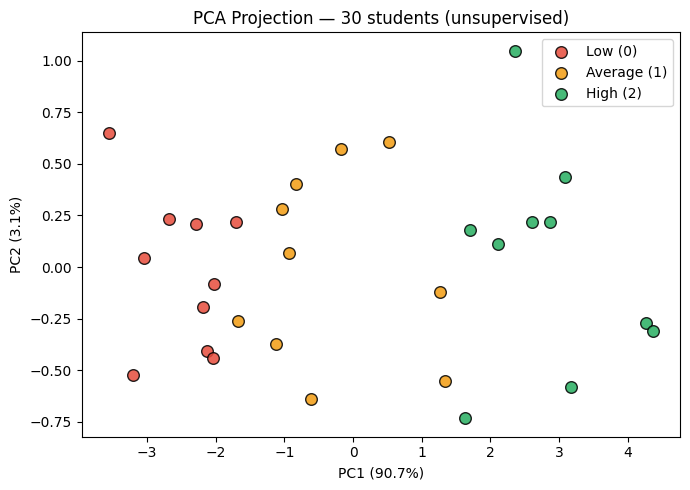

Explained variance ratio: [0.907 0.031]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


np.random.seed(42)
n = 30
ability = np.random.uniform(0, 1, n)

df = pd.DataFrame({
    'StudyHours': 1  + 9  * ability + np.random.normal(0, 1.0, n),
    'Attendance': 50 + 50 * ability + np.random.normal(0, 5.0, n),
    'Assignment': 30 + 70 * ability + np.random.normal(0, 8.0, n),
    'Internal':   30 + 70 * ability + np.random.normal(0, 8.0, n),
    'Practical':  30 + 70 * ability + np.random.normal(0, 8.0, n),
    'Test':       30 + 70 * ability + np.random.normal(0, 8.0, n),
}).clip(lower=0)

score = df[['Attendance','Assignment','Internal','Practical','Test']].mean(axis=1)
y = pd.qcut(score, q=3, labels=[0, 1, 2]).astype(int).values
print("Class counts:", np.bincount(y))       # → [10 10 10]

X = df.values

X_std = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

plt.figure(figsize=(7, 5))
colors = ['#e74c3c', '#f39c12', '#27ae60']
names  = ['Low (0)', 'Average (1)', 'High (2)']
for i, (c, nm) in enumerate(zip(colors, names)):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1],
                c=c, label=nm, s=70, alpha=0.85, edgecolor='k')
plt.title('PCA Projection — 30 students (unsupervised)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(); plt.tight_layout(); plt.show()

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))

STUDENT DATASET (30 students)
    StudyHours  Attendance  Assignment  Internal  Practical  Test  Performance
0          2.0          50          40        38         42    40            0
1          1.0          45          35        32         38    35            0
2          3.0          55          45        42         48    44            0
3          2.0          48          38        35         40    37            0
4          1.5          42          32        30         35    33            0
5          2.5          58          48        45         50    46            0
6          3.0          52          42        40         45    41            0
7          1.0          40          30        28         32    30            0
8          2.0          50          40        38         42    39            0
9          2.5          55          44        41         46    43            0
10         4.0          65          55        52         58    54            1
11         5.0        

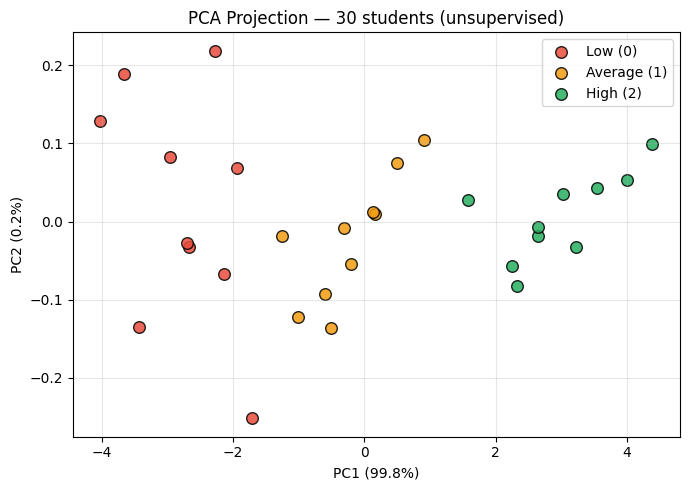


PCA explained variance ratio: [0.998 0.002]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = [
    # StudyHours, Attendance, Assignment, Internal, Practical, Test, Performance
    [2.0, 50, 40, 38, 42, 40, 0],   # Low performance
    [1.0, 45, 35, 32, 38, 35, 0],
    [3.0, 55, 45, 42, 48, 44, 0],
    [2.0, 48, 38, 35, 40, 37, 0],
    [1.5, 42, 32, 30, 35, 33, 0],
    [2.5, 58, 48, 45, 50, 46, 0],
    [3.0, 52, 42, 40, 45, 41, 0],
    [1.0, 40, 30, 28, 32, 30, 0],
    [2.0, 50, 40, 38, 42, 39, 0],
    [2.5, 55, 44, 41, 46, 43, 0],
    [4.0, 65, 55, 52, 58, 54, 1],   # Average performance
    [5.0, 70, 60, 58, 62, 59, 1],
    [3.5, 62, 52, 50, 55, 51, 1],
    [4.5, 68, 58, 55, 60, 56, 1],
    [5.5, 72, 62, 60, 65, 61, 1],
    [4.0, 66, 56, 53, 58, 55, 1],
    [3.5, 60, 50, 48, 53, 49, 1],
    [6.0, 75, 65, 62, 68, 64, 1],
    [5.0, 70, 60, 57, 63, 58, 1],
    [4.5, 67, 57, 54, 59, 56, 1],
    [7.0, 85, 75, 72, 78, 74, 2],   # High performance
    [8.0, 90, 82, 80, 85, 81, 2],
    [6.5, 80, 70, 68, 72, 69, 2],
    [9.0, 95, 88, 85, 90, 86, 2],
    [7.5, 88, 78, 75, 80, 76, 2],
    [8.5, 92, 84, 82, 87, 83, 2],
    [7.0, 85, 76, 73, 78, 75, 2],
    [9.5, 98, 90, 88, 92, 89, 2],
    [8.0, 90, 80, 78, 83, 79, 2],
    [7.5, 87, 78, 75, 80, 77, 2],
]

cols = ['StudyHours','Attendance','Assignment','Internal','Practical','Test','Performance']
df = pd.DataFrame(data, columns=cols)

print("=" * 70)
print("STUDENT DATASET (30 students)")
print("=" * 70)
print(df.to_string(index=True))
print("\nClass counts (0=Low, 1=Avg, 2=High):")
print(df['Performance'].value_counts().sort_index())
print("=" * 70)

X = df.drop('Performance', axis=1).values
y = df['Performance'].values
X_std = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

plt.figure(figsize=(7, 5))
colors = ['#e74c3c', '#f39c12', '#27ae60']
names  = ['Low (0)', 'Average (1)', 'High (2)']
for i, (c, nm) in enumerate(zip(colors, names)):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1],
                c=c, label=nm, s=70, alpha=0.85, edgecolor='k')
plt.title('PCA Projection — 30 students (unsupervised)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print("\nPCA explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))

STUDENT DATASET (30 students)
    StudyHours  Attendance  Assignment  Internal  Practical  Test  Performance
0          2.0          50          40        38         42    40            0
1          1.0          45          35        32         38    35            0
2          3.0          55          45        42         48    44            0
3          2.0          48          38        35         40    37            0
4          1.5          42          32        30         35    33            0
5          2.5          58          48        45         50    46            0
6          3.0          52          42        40         45    41            0
7          1.0          40          30        28         32    30            0
8          2.0          50          40        38         42    39            0
9          2.5          55          44        41         46    43            0
10         4.0          65          55        52         58    54            1
11         5.0        

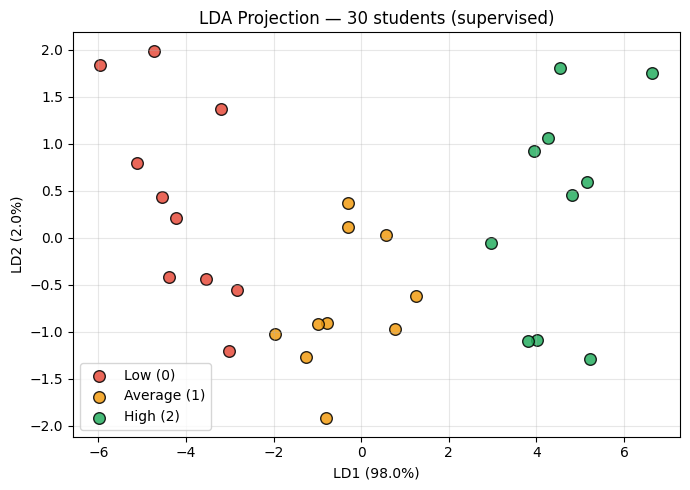


LDA explained variance ratio: [0.98 0.02]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# ---------- 1. HARDCODED dataset (30 students, identical) ----------
data = [
    [2.0, 50, 40, 38, 42, 40, 0],
    [1.0, 45, 35, 32, 38, 35, 0],
    [3.0, 55, 45, 42, 48, 44, 0],
    [2.0, 48, 38, 35, 40, 37, 0],
    [1.5, 42, 32, 30, 35, 33, 0],
    [2.5, 58, 48, 45, 50, 46, 0],
    [3.0, 52, 42, 40, 45, 41, 0],
    [1.0, 40, 30, 28, 32, 30, 0],
    [2.0, 50, 40, 38, 42, 39, 0],
    [2.5, 55, 44, 41, 46, 43, 0],
    [4.0, 65, 55, 52, 58, 54, 1],
    [5.0, 70, 60, 58, 62, 59, 1],
    [3.5, 62, 52, 50, 55, 51, 1],
    [4.5, 68, 58, 55, 60, 56, 1],
    [5.5, 72, 62, 60, 65, 61, 1],
    [4.0, 66, 56, 53, 58, 55, 1],
    [3.5, 60, 50, 48, 53, 49, 1],
    [6.0, 75, 65, 62, 68, 64, 1],
    [5.0, 70, 60, 57, 63, 58, 1],
    [4.5, 67, 57, 54, 59, 56, 1],
    [7.0, 85, 75, 72, 78, 74, 2],
    [8.0, 90, 82, 80, 85, 81, 2],
    [6.5, 80, 70, 68, 72, 69, 2],
    [9.0, 95, 88, 85, 90, 86, 2],
    [7.5, 88, 78, 75, 80, 76, 2],
    [8.5, 92, 84, 82, 87, 83, 2],
    [7.0, 85, 76, 73, 78, 75, 2],
    [9.5, 98, 90, 88, 92, 89, 2],
    [8.0, 90, 80, 78, 83, 79, 2],
    [7.5, 87, 78, 75, 80, 77, 2],
]

cols = ['StudyHours','Attendance','Assignment','Internal','Practical','Test','Performance']
df = pd.DataFrame(data, columns=cols)

# ---------- 2. PRINT the dataset ----------
print("=" * 70)
print("STUDENT DATASET (30 students)")
print("=" * 70)
print(df.to_string(index=True))
print("\nClass counts (0=Low, 1=Avg, 2=High):")
print(df['Performance'].value_counts().sort_index())
print("=" * 70)

# ---------- 3. Prepare X and y ----------
X = df.drop('Performance', axis=1).values
y = df['Performance'].values
X_std = StandardScaler().fit_transform(X)

# ---------- 4. LDA (uses labels; max 2 components for 3 classes) ----------
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X_std, y)

# ---------- 5. Plot ----------
plt.figure(figsize=(7, 5))
colors = ['#e74c3c', '#f39c12', '#27ae60']
names  = ['Low (0)', 'Average (1)', 'High (2)']
for i, (c, nm) in enumerate(zip(colors, names)):
    plt.scatter(X_lda[y == i, 0], X_lda[y == i, 1],
                c=c, label=nm, s=70, alpha=0.85, edgecolor='k')
plt.title('LDA Projection — 30 students (supervised)')
plt.xlabel(f'LD1 ({lda.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'LD2 ({lda.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print("\nLDA explained variance ratio:", np.round(lda.explained_variance_ratio_, 3))